# TAM400: VPN or NonVPN Traffic Classification
## Complete project in one notebook

**Student 1:** [full name] | **Student 2:** [full name] | **Group:** [number]

**Research question:** Can a model distinguish VPN from NonVPN network flows using nine numerical traffic measurements?

**How to use this notebook:** Upload this one `.ipynb` file to Google Colab and run the cells from top to bottom on a normal CPU runtime. The notebook downloads the raw dataset, prepares it, trains the models, compares them, tests the selected model and displays the final results here.

**No other notebook, saved model or result file is needed.** All training and evaluation happen in the code cells below. Tables and figures appear directly below the code. The supplied notebook includes saved outputs. Running all cells in Colab recomputes the results using the active runtime. The first code cell prints the library versions used by that run.

The target is **NonVPN = 0** or **VPN = 1**. Each row represents a network flow, not an individual user. This is an offline experiment using labelled data.

## 1. Import the libraries
These libraries are normally available in Colab. The first cell installs a library only if it is missing.

In [ ]:
import importlib.util
import subprocess
import sys

packages = {"sklearn": "scikit-learn", "pandas": "pandas",
            "numpy": "numpy", "matplotlib": "matplotlib"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

from pathlib import Path
from io import StringIO
from urllib.request import urlretrieve
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.13.15
scikit-learn: 1.6.1
pandas: 2.2.3
NumPy: 2.1.3


## 2. Download and inspect the raw dataset
We use the ISCXVPN2016 dataset described by the **Canadian Institute for Cybersecurity at the University of New Brunswick, Canada**. It contains labelled traffic recorded with and without a VPN. The original university description and paper explain how the data was collected.

- **Original dataset source:** https://www.unb.ca/cic/datasets/vpn.html
- **Research paper:** https://doi.org/10.5220/0005740704070414
- **Exact feature-file copy used here:** https://github.com/shafwanur/thd-ss25-ml-project/blob/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff

Our code downloads this fixed public copy of the feature file for a 15-second flow timeout. Only the **raw data** is downloaded. The checksum checks that we have the expected copy each time. It does **not** verify that the copy is identical to the university archive. The official download route leads to a registration form. We have not independently compared our copy with that archive.

ARFF files have a header followed by comma-separated data rows. `class1` contains the original application labels.

In [ ]:
url = "https://raw.githubusercontent.com/shafwanur/thd-ss25-ml-project/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff"
expected_hash = "8b12e8c0cd49f56af28cdaa7c2aa7795ee24de0b1bedf638280e00404f7c1563"
data_file = Path("15s.arff")
if not data_file.exists():
    urlretrieve(url, data_file)
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == expected_hash, "Unexpected dataset file"

# Read the ARFF column names and then its data rows.
lines = data_file.read_text().splitlines()
columns = [line.split()[1] for line in lines if line.upper().startswith("@ATTRIBUTE")]
start = next(i for i, line in enumerate(lines) if line.upper().startswith("@DATA")) + 1
df = pd.read_csv(StringIO("\n".join(lines[start:])), names=columns)
print("Raw rows and columns:", df.shape)
display(df.head())

Raw rows and columns: (18758, 24)


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,...,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,class1
0,9368711,16,4,1564818,1549373,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,...,267600.198443,1871488,1.983656e+06,2195089,1.832197e+05,1234883,1420565.0,1523088,161096.539275,CHAT
1,7340238,18,4,1567554,1527893,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,...,221462.862028,1491627,3.572433e+06,5653239,2.942704e+06,1131498,1324636.0,1517774,273138.379008,CHAT
2,4644225,29,15,1270547,1079974,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,...,217475.425246,1758922,1.758922e+06,1758922,0.000000e+00,1079974,1079974.0,1079974,0.000000,CHAT
3,4978735,19,8,2492050,2457286,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,...,436959.716436,1710925,2.382905e+06,3054885,9.503232e+05,1346073,1894031.5,2441990,774930.342317,CHAT
4,11838189,19,10,3094089,3093543,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,...,436129.639296,1747431,2.400446e+06,3240696,6.232744e+05,1394455,1983227.0,3042717,725987.829075,CHAT


## 3. Create the inputs and target, then clean the data
We select nine numerical measurements to keep the project small. `class1` is used only to create the target; including it in the inputs would reveal the answer.

Negative durations and traffic rates are invalid, so we replace them with missing values. We first keep one copy of identical input-and-label rows. If an input vector still occurs more than once, it has conflicting labels, so we remove both versions. These cleaning rules are specific to this dataset.

In [ ]:
features = ["duration", "flowPktsPerSecond", "flowBytesPerSecond",
            "min_flowiat", "max_flowiat", "mean_flowiat", "std_flowiat",
            "mean_active", "mean_idle"]
X = df[features].copy()
y = df["class1"].str.strip().str.upper().str.startswith("VPN-").astype(int).rename("vpn")

negative_cells = int((X < 0).sum().sum())
X[X < 0] = np.nan
clean = pd.concat([X, y], axis=1)
clean = clean.drop_duplicates()  # Keep one row when both inputs and label are identical.
clean = clean.drop_duplicates(subset=features, keep=False)  # Remove conflicting labels.
removed_rows = len(df) - len(clean)
X, y = clean[features], clean["vpn"]

print("Invalid negative cells replaced with missing values:", negative_cells)
print("Duplicate or conflicting rows removed:", removed_rows)
print("Clean rows:", len(clean))
print("Number of input features:", X.shape[1])

Invalid negative cells replaced with missing values: 1240
Duplicate or conflicting rows removed: 779
Clean rows: 17979
Number of input features: 9


## 4. Split the data into training and test sets
We use **80% for training** and **20% for testing**, with `random_state=42` for reproducibility. Stratification preserves the class proportions.

We compare and tune models using cross-validation inside the training set. The test set is used after model selection. This same test partition was examined in earlier project versions, so it is a reused development test rather than a new independent evaluation.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print("Training flows:", len(X_train))
print("Test flows:", len(X_test))
print("Training class counts (0 = NonVPN, 1 = VPN):")
print(y_train.value_counts().sort_index())

Training flows: 14383
Test flows: 3596
Training class counts (0 = NonVPN, 1 = VPN):
vpn
0    6927
1    7456
Name: count, dtype: int64


## 5. Explore the training data
We display a class-count plot, a raw histogram and a simple correlation table to explore the training data. We do not change the nine selected inputs based on these plots.

`corr(numeric_only=True)` uses Pearson correlation. A positive value indicates a positive linear association with VPN=1; a negative value indicates a negative association. Values near zero do not rule out nonlinear relationships. Duration remains in the source dataset's units.

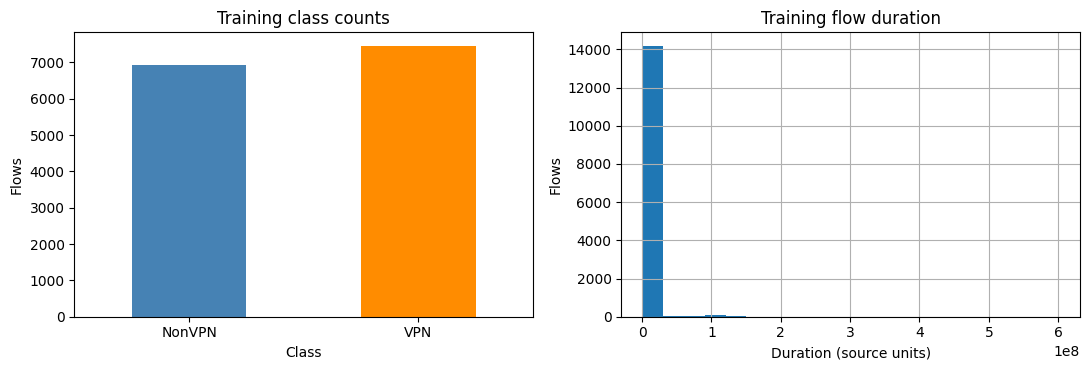

,Feature,Pearson correlation with VPN
0,mean_flowiat,0.0532
1,min_flowiat,0.0378
2,std_flowiat,0.0050
3,flowPktsPerSecond,0.0007
4,mean_active,-0.0077
5,max_flowiat,-0.0133
6,mean_idle,-0.0151
7,flowBytesPerSecond,-0.0347
8,duration,-0.0670


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
y_train.value_counts().sort_index().plot.bar(ax=axes[0], color=["steelblue", "darkorange"])
axes[0].set(xticklabels=["NonVPN", "VPN"], xlabel="Class", ylabel="Flows", title="Training class counts")
axes[0].tick_params(axis="x", rotation=0)
X_train["duration"].hist(bins=20, ax=axes[1])
axes[1].set(xlabel="Duration (source units)", ylabel="Flows", title="Training flow duration")
plt.tight_layout()
plt.show()

training_data = X_train.copy()
training_data["vpn"] = y_train
correlation = training_data.corr(numeric_only=True)
correlation_table = correlation["vpn"].drop("vpn").sort_values(ascending=False)
display(correlation_table.rename_axis("Feature").reset_index(name="Pearson correlation with VPN").round(4))

## 6. Train the baseline
We use `DummyClassifier` as our reference model. We call it the **baseline**. Our `strategy="most_frequent"` setting makes it predict the most common training class for every flow. This lets us check whether the other models improve on a simple prediction rule.

Every pipeline fits its median imputer on training data only. Keeping preprocessing inside the pipeline also protects the validation folds.

In [ ]:
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DummyClassifier(strategy="most_frequent"))
])
baseline.fit(X_train, y_train)
print("Baseline trained on", len(X_train), "flows.")

Baseline trained on 14383 flows.


## 7. Train SGDClassifier
`SGDClassifier` learns a linear decision boundary. We add `StandardScaler` because the numerical inputs have very different ranges. The scaler is fitted inside the pipeline.

In [ ]:
sgd_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SGDClassifier(random_state=42))
])
sgd_model.fit(X_train, y_train)
print("SGDClassifier trained on", len(X_train), "flows.")

SGDClassifier trained on 14383 flows.


## 8. Train RandomForestClassifier
`RandomForestClassifier` combines multiple decision trees. We use the default model settings and `random_state=42`. This classifier does not require standard scaling.

In [ ]:
forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(random_state=42))
])
forest_model.fit(X_train, y_train)
print("Random Forest trained on", len(X_train), "flows.")
print("Number of trees:", forest_model.named_steps["model"].n_estimators)

Random Forest trained on 14383 flows.
Number of trees: 100


## 9. Check training accuracy
These scores use data the models have already seen. High training accuracy alone does not show that a model works well on new data. We therefore compare validation scores in the next section.

In [ ]:
pipelines = {"Baseline": baseline, "SGDClassifier": sgd_model, "Random Forest": forest_model}
training_rows = []
for name, model in pipelines.items():
    prediction = model.predict(X_train)
    training_rows.append({"Model": name, "Training accuracy": accuracy_score(y_train, prediction)})
training_results = pd.DataFrame(training_rows)
display(training_results.round(4))

,Model,Training accuracy
0,Baseline,0.5184
1,SGDClassifier,0.5893
2,Random Forest,0.9999


## 10. Compare the models with cross-validation
We use three stratified folds within the training set. Each model is trained on two folds and evaluated on the remaining fold, repeating this for all three folds.

We compare **VPN F1**, which combines precision and recall. Higher is better. Model comparison does not use test-set scores.

,Model,CV F1 mean,CV F1 std
2,Random Forest,0.8935,0.004
0,Baseline,0.6828,0.000
1,SGDClassifier,0.6003,0.071


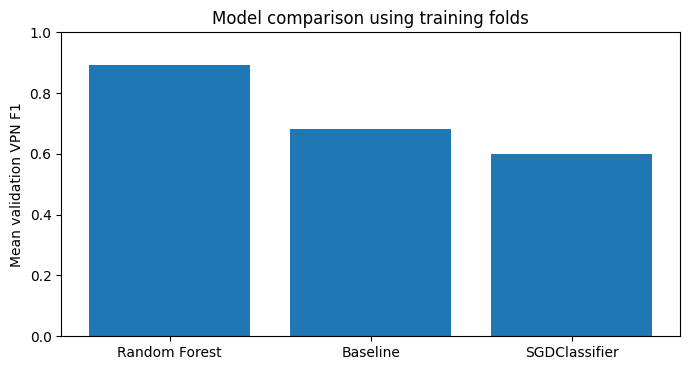

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_scores = {}
for name, model in pipelines.items():
    cv_scores[name] = cross_val_score(model, X_train, y_train, scoring="f1", cv=cv)

comparison = pd.DataFrame({
    "Model": list(cv_scores),
    "CV F1 mean": [scores.mean() for scores in cv_scores.values()],
    "CV F1 std": [scores.std() for scores in cv_scores.values()]
}).sort_values("CV F1 mean", ascending=False)
display(comparison.round(4))

plt.figure(figsize=(7, 3.8))
plt.bar(comparison["Model"], comparison["CV F1 mean"])
plt.ylim(0, 1)
plt.ylabel("Mean validation VPN F1")
plt.title("Model comparison using training folds")
plt.tight_layout()
plt.show()

## 11. Try three Random Forest settings
We use `GridSearchCV` to test `max_features` values of **4, 6 and 8**. This parameter controls how many input features are considered at each tree split. We compare these settings for our Random Forest classifier.

The final model is the best of the initial models and the best grid-search candidate, according to mean validation F1. The grid does not have to improve the model. Because the same folds support selection and tuning, the highest validation score is a selection score, not an independent performance estimate.

In [ ]:
grid = {"model__max_features": [4, 6, 8]}
search = GridSearchCV(forest_model, grid, scoring="f1", cv=cv)
search.fit(X_train, y_train)

tuning = pd.DataFrame(search.cv_results_)
tuning_table = tuning[["param_model__max_features", "mean_test_score", "std_test_score"]].rename(
    columns={"param_model__max_features": "max_features",
             "mean_test_score": "Mean validation F1", "std_test_score": "Fold standard deviation"})
display(tuning_table.round(4))

best_name = comparison.iloc[0]["Model"]
final_model = pipelines[best_name]
best_cv_f1 = float(comparison.iloc[0]["CV F1 mean"])
grid_improved = bool(search.best_score_ > best_cv_f1)
if grid_improved:
    best_name = "Random Forest tuned"
    final_model = search.best_estimator_
    best_cv_f1 = float(search.best_score_)

print("Best max_features in the grid:", search.best_params_["model__max_features"])
print("Best grid validation F1:", round(search.best_score_, 4))
print("Did the grid improve on the best initial model?", grid_improved)
print("Selected model:", best_name)
print("Selected model validation F1:", round(best_cv_f1, 4))
if best_name.startswith("Random Forest"):
    print("Selected model max_features:", final_model.named_steps["model"].max_features)

,max_features,Mean validation F1,Fold standard deviation
0,4,0.8932,0.0044
1,6,0.8932,0.0039
2,8,0.8917,0.0016


Best max_features in the grid: 6
Best grid validation F1: 0.8932
Did the grid improve on the best initial model? False
Selected model: Random Forest
Selected model validation F1: 0.8935
Selected model max_features: sqrt


## 12. Evaluate the selected model on the test set
The model has now been selected. We evaluate it and the baseline on the test data, using the following measures:

- **Accuracy:** fraction of all predictions that are correct.
- **VPN precision:** fraction of VPN predictions that are correct.
- **VPN recall:** fraction of actual VPN flows detected.
- **VPN F1:** harmonic mean of precision and recall.
- **ROC-AUC:** how well the model's scores rank VPN above NonVPN flows.

The models used here were trained in this notebook. No saved model or result file is loaded.

In [ ]:
test_rows = []
for name, model in [(best_name, final_model), ("Baseline", baseline)]:
    prediction = model.predict(X_test)
    scores = model.decision_function(X_test) if name == "SGDClassifier" else model.predict_proba(X_test)[:, 1]
    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "VPN precision": precision_score(y_test, prediction, zero_division=0),
        "VPN recall": recall_score(y_test, prediction, zero_division=0),
        "VPN F1": f1_score(y_test, prediction, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })
results = pd.DataFrame(test_rows)
display(results.round(4))

,Model,Accuracy,VPN precision,VPN recall,VPN F1,ROC-AUC
0,Random Forest,0.9077,0.9010,0.9233,0.9120,0.9678
1,Baseline,0.5184,0.5184,1.0000,0.6828,0.5000


## 13. Examine the errors
The confusion matrix shows the number of correct and incorrect predictions. Rows are actual classes; columns are predicted classes.

A **false VPN alarm** is a NonVPN flow predicted as VPN. A **missed VPN flow** is a VPN flow predicted as NonVPN.

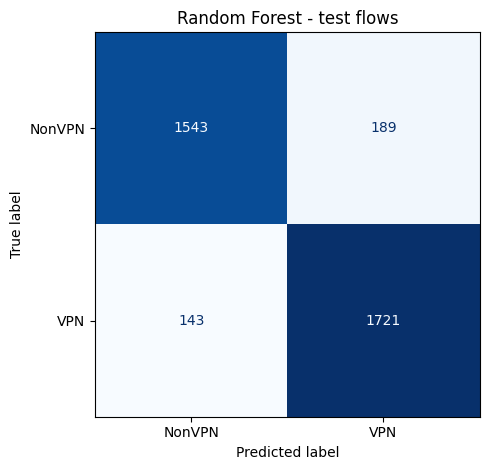

False VPN alarms: 189
Missed VPN flows: 143


In [ ]:
final_prediction = final_model.predict(X_test)
cm = confusion_matrix(y_test, final_prediction, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["NonVPN", "VPN"]).plot(cmap="Blues", colorbar=False)
plt.title(best_name + " - test flows")
plt.tight_layout()
plt.show()
print("False VPN alarms:", cm[0, 1])
print("Missed VPN flows:", cm[1, 0])

## 14. Compare example predictions with the true labels
These examples come from the test set. They demonstrate the predictions made by the model trained above; they do not inspect the current internet connection.

In [ ]:
predictions = pd.DataFrame({
    "Source row": X_test.index,
    "Actual": np.where(y_test == 1, "VPN", "NonVPN"),
    "Predicted": np.where(final_prediction == 1, "VPN", "NonVPN")
})
display(predictions.head(10))

,Source row,Actual,Predicted
0,15291,VPN,NonVPN
1,4257,NonVPN,NonVPN
2,1260,NonVPN,NonVPN
3,2990,NonVPN,NonVPN
4,18400,NonVPN,NonVPN
5,8769,VPN,VPN
6,8271,VPN,VPN
7,9953,VPN,VPN
8,5218,NonVPN,NonVPN
9,886,NonVPN,VPN


## 15. Final results from this run
The following cell calculates the final summary from the model and predictions produced above. It updates when the notebook is run again.

In [ ]:
selected_results = results.iloc[0]
train_accuracy = accuracy_score(y_train, final_model.predict(X_train))
print("FINAL RESULTS")
print("Selected model:", best_name)
print("Training flows:", len(X_train), "| Test flows:", len(X_test))
print(f"Validation VPN F1: {best_cv_f1:.4f}")
print(f"Test accuracy: {selected_results['Accuracy']:.2%}")
print(f"Test VPN precision: {selected_results['VPN precision']:.2%}")
print(f"Test VPN recall: {selected_results['VPN recall']:.2%}")
print(f"Test VPN F1: {selected_results['VPN F1']:.4f}")
print(f"Test ROC-AUC: {selected_results['ROC-AUC']:.4f}")
print("False VPN alarms:", cm[0, 1], "| Missed VPN flows:", cm[1, 0])
print(f"Training accuracy: {train_accuracy:.3%}")
print(f"Training-test accuracy gap: {(train_accuracy - selected_results['Accuracy']) * 100:.2f} percentage points")
print("Grid search improved the best initial model:", grid_improved)

baseline_f1 = comparison.loc[comparison["Model"] == "Baseline", "CV F1 mean"].iloc[0]
sgd_f1 = comparison.loc[comparison["Model"] == "SGDClassifier", "CV F1 mean"].iloc[0]
print("SGDClassifier exceeded the baseline validation F1:", bool(sgd_f1 > baseline_f1))

FINAL RESULTS
Selected model: Random Forest
Training flows: 14383 | Test flows: 3596
Validation VPN F1: 0.8935
Test accuracy: 90.77%
Test VPN precision: 90.10%
Test VPN recall: 92.33%
Test VPN F1: 0.9120
Test ROC-AUC: 0.9678
False VPN alarms: 189 | Missed VPN flows: 143
Training accuracy: 99.993%
Training-test accuracy gap: 9.23 percentage points
Grid search improved the best initial model: False
SGDClassifier exceeded the baseline validation F1: False


## 16. Interpretation and limitations

In the supplied execution, Random Forest performed best. The three grid-search settings did not improve on the original forest, so the original model was retained. SGDClassifier had lower validation F1 than the baseline. Reporting that unsuccessful comparison is part of the experiment.

Random Forest's nearly perfect training accuracy is higher than its test accuracy, which indicates overfitting. Use the final results cell above for the exact values from the current run.

- The same test partition was examined in earlier project versions. It is a development test, not fresh independent confirmation.
- Conflicting observations were removed. The results apply to the cleaned dataset and may be better than results that include those difficult cases.
- Session identifiers are unavailable. Related flows may appear in both training and test data, even after exact duplicates are removed.
- The public data copy has not been compared with the original archive. The traffic is historical and does not represent every current VPN environment.
- A useful next step is to evaluate entirely new traffic captures independently of the training data.

**Save this notebook with its cell outputs.** The teacher can inspect the code, training, comparisons, test results and conclusion in this same file. No separate results download is required.

## 17. References and AI acknowledgment

1. G. Draper-Gil et al., *Characterization of Encrypted and VPN Traffic using Time-related Features*, ICISSP 2016, pp. 407-414. https://doi.org/10.5220/0005740704070414
2. Official dataset description: https://www.unb.ca/cic/datasets/vpn.html
3. Version-pinned data copy: https://github.com/shafwanur/thd-ss25-ml-project/blob/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff
4. scikit-learn documentation: https://scikit-learn.org/stable/modules/linear_model.html#sgd and https://scikit-learn.org/stable/modules/ensemble.html#forest
5. **Our project repository:** https://github.com/SAS2005/VPN-NonVPN-Classification-project

We used OpenAI Codex to explain course concepts and support the project work. Its help included finding data sources, generating and debugging code, running an earlier project version locally, preparing figures and drafting explanations. The reported results are the saved outputs included in this notebook. We are responsible for understanding and explaining the submitted work. The contribution fields below should describe what each group member actually did.

**Student 1 contribution:** [complete]  
**Student 2 contribution:** [complete]